In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('sales_data_sample.csv', encoding='latin1')

In [3]:
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   str    
 6   STATUS            2823 non-null   str    
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   str    
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   str    
 13  CUSTOMERNAME      2823 non-null   str    
 14  PHONE             2823 non-null   str    
 15  ADDRESSLINE1      2823 non-null   str    
 16  ADDRESSLINE2      302 non-null    str    
 17  CITY  

In [5]:
df.isnull().sum()

ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

In [6]:
# Extracting the features
X = df[['QUANTITYORDERED','PRICEEACH','SALES','MSRP']]

In [7]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

Note: you may need to restart the kernel to use updated packages.


In [8]:
X.isnull().sum()

QUANTITYORDERED    0
PRICEEACH          0
SALES              0
MSRP               0
dtype: int64

In [9]:
X = X.dropna()

In [10]:
# Scaling the data
s = StandardScaler()
X = s.fit_transform(X)

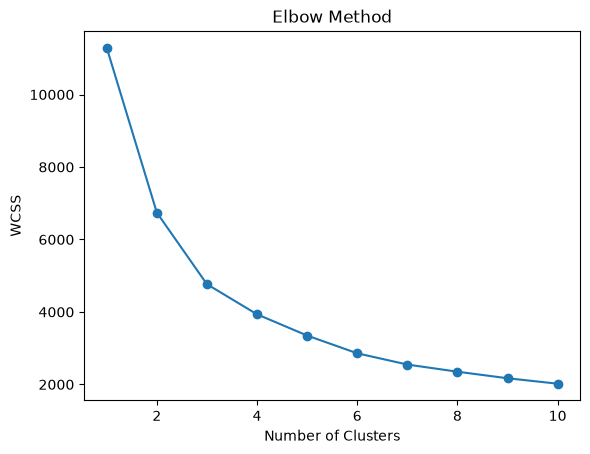

In [11]:
# Elbow Point
wcss = []
for i in range(1,11):
    km = KMeans(n_clusters=i,random_state=42,n_init=10)
    km.fit(X)
    wcss.append(km.inertia_)

plt.plot(range(1,11),wcss,marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

In [32]:
km = KMeans(n_clusters=4,random_state=42,n_init=10)
df['Cluster'] = km.fit_predict(X)
df[['QUANTITYORDERED','PRICEEACH','SALES','MSRP','Cluster']].head()

,QUANTITYORDERED,PRICEEACH,SALES,MSRP,Cluster
0,30,95.70,2871.00,95,1
1,34,81.35,2765.90,95,1
2,41,94.74,3884.34,95,0
3,45,83.26,3746.70,95,0
4,49,100.00,5205.27,95,2


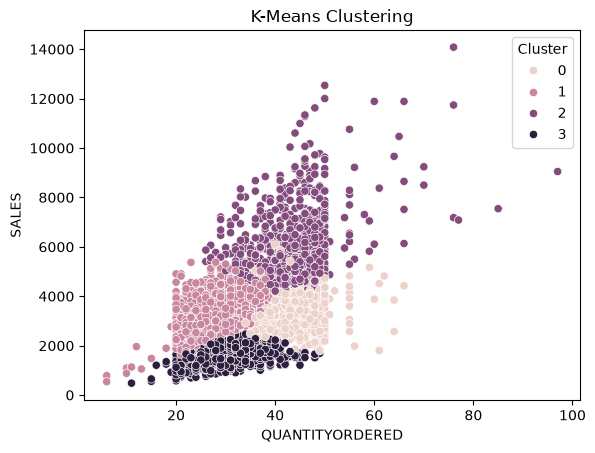

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(data=df, x='QUANTITYORDERED', y='SALES',
                hue='Cluster')

plt.title('K-Means Clustering')
plt.show()

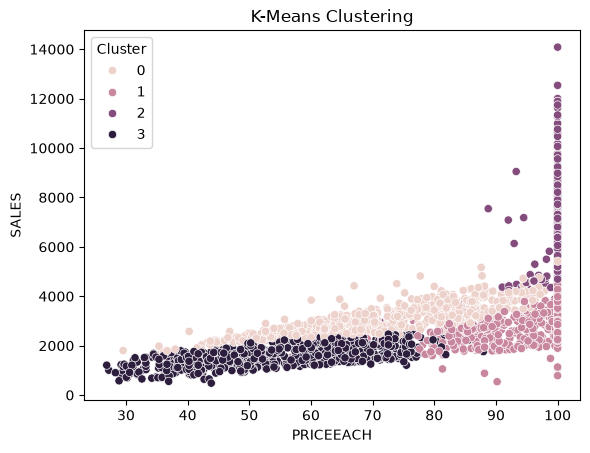

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(data=df, x='PRICEEACH', y='SALES',
                hue='Cluster')

plt.title('K-Means Clustering')
plt.show()

In [37]:
from sklearn.metrics import silhouette_score

print("Silhouette Score:", silhouette_score(X, df['Cluster']))

Silhouette Score: 0.34012677568622873


In [38]:
# Hierarchical Clustering
from sklearn.cluster import AgglomerativeClustering

In [52]:
hc = AgglomerativeClustering(n_clusters=4,linkage='ward')

In [53]:
df['HC'] = hc.fit_predict(X)

In [54]:
df[['QUANTITYORDERED','PRICEEACH','SALES','MSRP','HC']].head()

,QUANTITYORDERED,PRICEEACH,SALES,MSRP,HC
0,30,95.70,2871.00,95,2
1,34,81.35,2765.90,95,2
2,41,94.74,3884.34,95,3
3,45,83.26,3746.70,95,3
4,49,100.00,5205.27,95,0


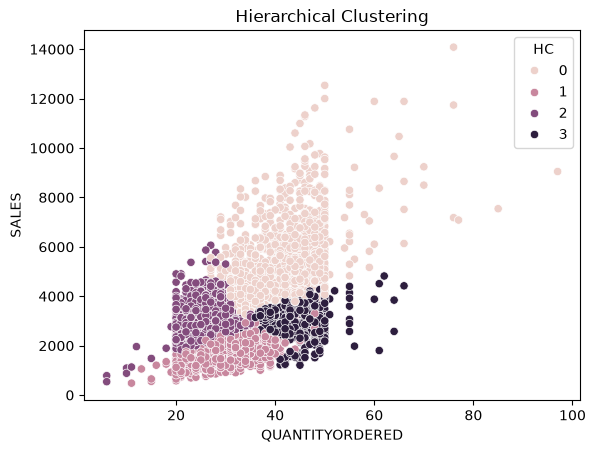

In [55]:
import seaborn as sns

sns.scatterplot(
    data=df,
    x='QUANTITYORDERED',
    y='SALES',
    hue='HC'
)

plt.title('Hierarchical Clustering')
plt.show()

In [56]:
from sklearn.metrics import silhouette_score

In [57]:
print(f"Silhoutte Score : {silhouette_score(X,df['HC'])}")

Silhoutte Score : 0.29009882858148506
